Total valid predictions: 1851

--- Prediction Distribution ---
predictions
1    1622
0     229
Name: count, dtype: int64


C:\Users\adver\AppData\Local\Temp\ipykernel_1064\2435263289.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='predictions', palette='viridis')


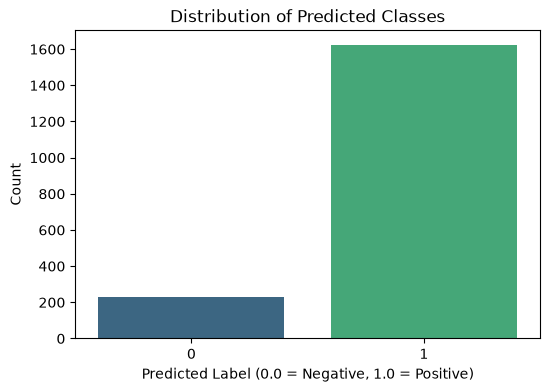

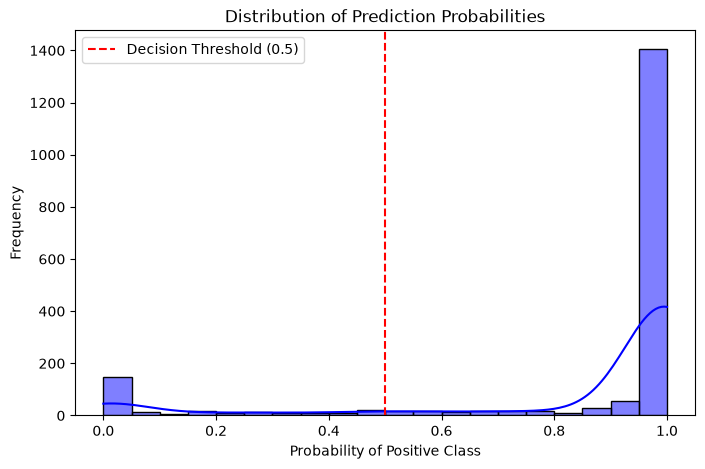


--- Ambiguous Cases (Probability near 0.5) ---
Prob: 0.5874 | Review: Our 6-year old wants to be a policeman when he grows up. He could not wait to get this belt. We had ...
Prob: 0.5158 | Review: These would of been 5 star slippers except the bottom sole of these were not rubber or another water...
Prob: 0.5677 | Review: i am still waiting for a credit to my credit card account. the item was not available and they said ...
Prob: 0.4678 | Review: These are adorable pumps, it's too bad I couldn't even put my foot down to walk in them. The heel is...
Prob: 0.5586 | Review: Positive: pretty light(not heavy), feel comfortable, and smooth

Negative: still might be foggy at s...
Prob: 0.5364 | Review: I was skeptical at first to buy this item because it seemed like too much money to spend on a simple...
Prob: 0.4606 | Review: Although quick, using the 8 pound ball proves to be a tough short workout...
Prob: 0.5858 | Review: Boots are warm & Cozy. However, the color was much lighter than pic

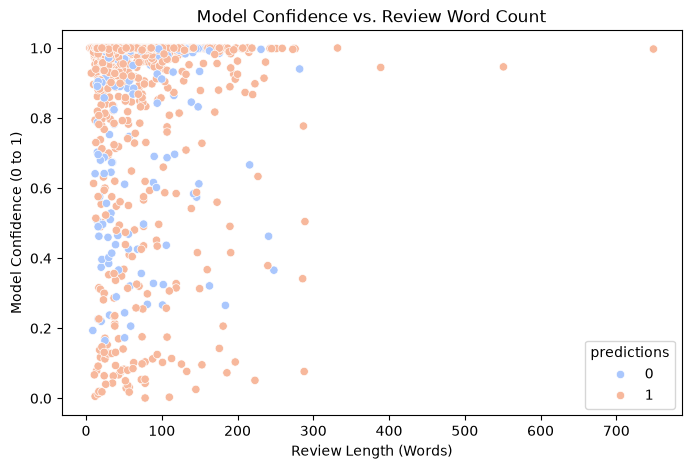

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Load and clean the data
df = pd.read_csv("test_predictions.csv")
# Drop rows where predictions are NaN (since the snippet has many empty rows)
df = df.dropna(subset=['predictions', 'prob_positive', 'reviews']).copy()

print(f"Total valid predictions: {len(df)}")

# 2. Prediction Distribution
print("\n--- Prediction Distribution ---")
print(df['predictions'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='predictions', palette='viridis')
plt.title('Distribution of Predicted Classes')
plt.xlabel('Predicted Label (0.0 = Negative, 1.0 = Positive)')
plt.ylabel('Count')
plt.show()

# 3. Confidence Spread (Probability Distribution)
plt.figure(figsize=(8, 5))
sns.histplot(df['prob_positive'], bins=20, kde=True, color='blue')
plt.title('Distribution of Prediction Probabilities')
plt.xlabel('Probability of Positive Class')
plt.ylabel('Frequency')
plt.axvline(0.5, color='red', linestyle='--', label='Decision Threshold (0.5)')
plt.legend()
plt.show()

# 4. Ambiguity and Edge-Case Analysis
# Find predictions where the model is least confident (probabilities between 0.4 and 0.6)
ambiguous_cases = df[(df['prob_positive'] >= 0.4) & (df['prob_positive'] <= 0.6)]
print("\n--- Ambiguous Cases (Probability near 0.5) ---")
if not ambiguous_cases.empty:
    for index, row in ambiguous_cases.iterrows():
        print(f"Prob: {row['prob_positive']:.4f} | Review: {row['reviews'][:100]}...")
else:
    print("No highly ambiguous cases found in this snippet.")

# 5. Review Length vs. Confidence
# Calculate confidence as absolute distance from 0.5 (scaled to 0-1)
df['confidence'] = abs(df['prob_positive'] - 0.5) * 2
df['review_length'] = df['reviews'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='review_length', y='confidence', hue='predictions', palette='coolwarm')
plt.title('Model Confidence vs. Review Word Count')
plt.xlabel('Review Length (Words)')
plt.ylabel('Model Confidence (0 to 1)')
plt.show()

In [2]:
def extract_flagged_predictions(comparison_file, test_file, output_file):
    # 1. Load both files
    df_comparison = pd.read_excel(comparison_file)
    df_test = pd.read_csv(test_file)
    
    # 2. Normalize the 'Flag' column to string to handle Excel's automatic boolean conversion
    df_comparison['Flag'] = df_comparison['Flag'].astype(str).str.strip().str.lower()
    
    # 3. Extract the set of reviews flagged as 'false'
    flagged_reviews = set(df_comparison[df_comparison['Flag'] == 'false']['review'].dropna())
    
    # 4. Filter the test_predictions dataframe
    # Removing the ~ operator keeps ONLY the rows where the review IS in the flagged set
    df_test_flagged_only = df_test[df_test['reviews'].isin(flagged_reviews)]
    
    # 5. Save the updated dataframe to a new Excel file without the index
    df_test_flagged_only.to_excel(output_file, index=False)
    
    # Print a summary of the changes
    original_count = len(df_test)
    flagged_count = len(df_test_flagged_only)
    print(f"Original row count: {original_count}")
    print(f"Extracted {flagged_count} flagged row(s).")
    print(f"File saved to: {output_file}")

# Execute the function referencing the files verbatim
extract_flagged_predictions(
    comparison_file="review_comparison.xlsx", 
    test_file="test_predictions_flags.csv", 
    output_file="flagged_test_predictions.xlsx"
)

Original row count: 1851
Extracted 101 flagged row(s).
File saved to: flagged_test_predictions.xlsx


Total valid predictions: 174

--- Prediction Distribution ---
predictions
1    153
0     21
Name: count, dtype: int64


C:\Users\adver\AppData\Local\Temp\ipykernel_1064\3728274374.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='predictions', palette='viridis')


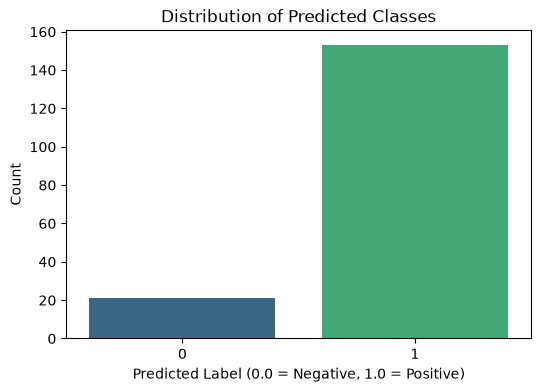

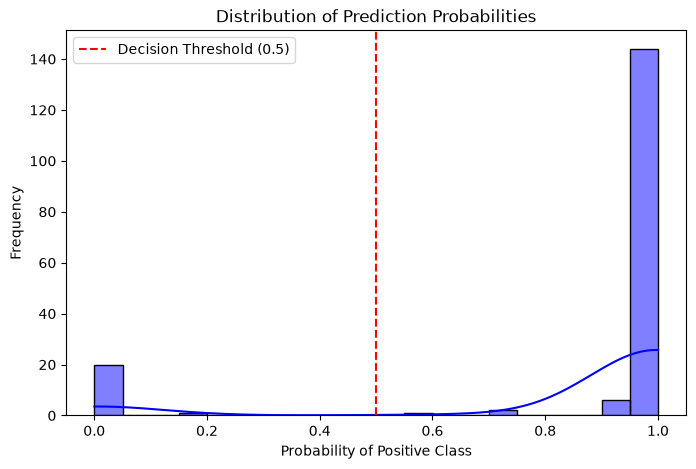


--- Ambiguous Cases (Probability near 0.5) ---
Prob: 0.5562 | Review: I had blisters and painful feet for 3 weeks until these shoes broke in.  If you buy these, make sure...


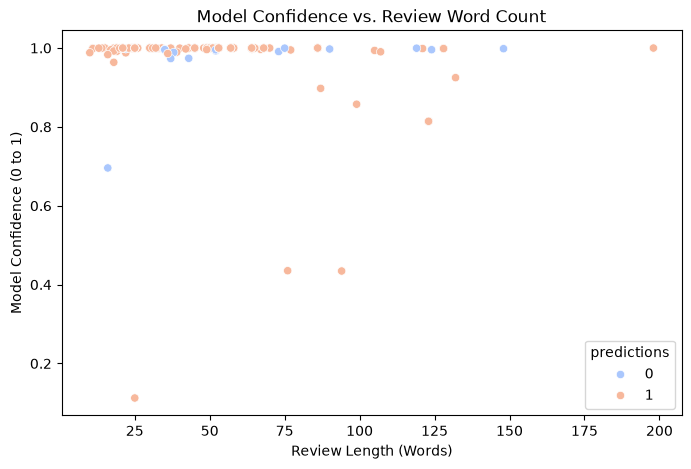

In [3]:
# 1. Load and clean the data
df = pd.read_excel("flagged_predictions_with_sentiments.xlsx")
# Drop rows where predictions are NaN (since the snippet has many empty rows)
df = df.dropna(subset=['predictions', 'prob_positive', 'reviews']).copy()

print(f"Total valid predictions: {len(df)}")

# 2. Prediction Distribution
print("\n--- Prediction Distribution ---")
print(df['predictions'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='predictions', palette='viridis')
plt.title('Distribution of Predicted Classes')
plt.xlabel('Predicted Label (0.0 = Negative, 1.0 = Positive)')
plt.ylabel('Count')
plt.show()

# 3. Confidence Spread (Probability Distribution)
plt.figure(figsize=(8, 5))
sns.histplot(df['prob_positive'], bins=20, kde=True, color='blue')
plt.title('Distribution of Prediction Probabilities')
plt.xlabel('Probability of Positive Class')
plt.ylabel('Frequency')
plt.axvline(0.5, color='red', linestyle='--', label='Decision Threshold (0.5)')
plt.legend()
plt.show()

# 4. Ambiguity and Edge-Case Analysis
# Find predictions where the model is least confident (probabilities between 0.4 and 0.6)
ambiguous_cases = df[(df['prob_positive'] >= 0.4) & (df['prob_positive'] <= 0.6)]
print("\n--- Ambiguous Cases (Probability near 0.5) ---")
if not ambiguous_cases.empty:
    for index, row in ambiguous_cases.iterrows():
        print(f"Prob: {row['prob_positive']:.4f} | Review: {row['reviews'][:100]}...")
else:
    print("No highly ambiguous cases found in this snippet.")

# 5. Review Length vs. Confidence
# Calculate confidence as absolute distance from 0.5 (scaled to 0-1)
df['confidence'] = abs(df['prob_positive'] - 0.5) * 2
df['review_length'] = df['reviews'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='review_length', y='confidence', hue='predictions', palette='coolwarm')
plt.title('Model Confidence vs. Review Word Count')
plt.xlabel('Review Length (Words)')
plt.ylabel('Model Confidence (0 to 1)')
plt.show()


--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.95      0.98        22
           1       0.99      1.00      1.00       152

    accuracy                           0.99       174
   macro avg       1.00      0.98      0.99       174
weighted avg       0.99      0.99      0.99       174

Accuracy:  0.9943
Precision: 0.9935
Recall:    1.0000
F1-Score:  0.9967


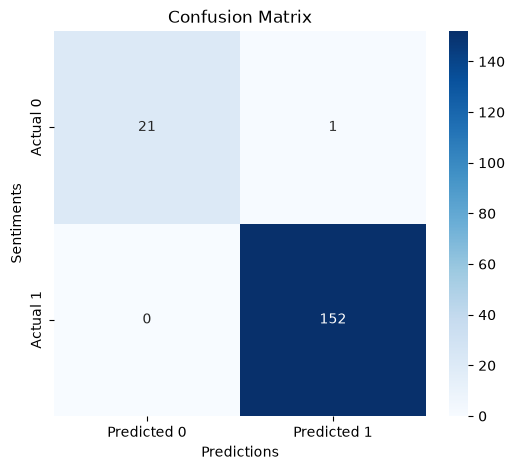

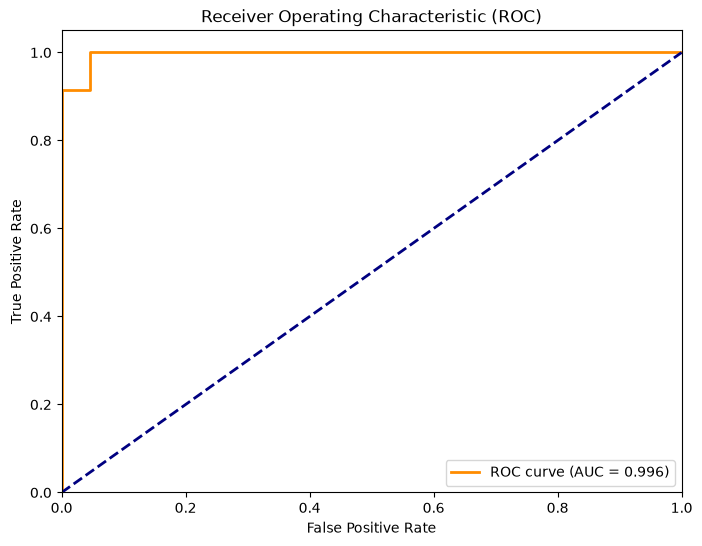


--- False Positives (1) ---
   prob_positive                                            reviews
7        0.99388  The soles of these shoes are very comfortable ...

--- False Negatives (0) ---
Empty DataFrame
Columns: [prob_positive, reviews]
Index: []


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# 1. Load the data (assuming a 'true_label' column has been added)
df = pd.read_excel("flagged_predictions_with_sentiments.xlsx")
df = df.dropna(subset=['predictions', 'prob_positive', 'sentiments']).copy()

# 2. Classification Metrics
y_true = df['sentiments']
y_pred = df['predictions']
y_prob = df['prob_positive']

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred))

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted 0', 'Predicted 1'], 
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Confusion Matrix')
plt.ylabel('Sentiments')
plt.xlabel('Predictions')
plt.show()

# 4. ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

# 5. Error Analysis (Isolating False Positives and False Negatives)
false_positives = df[(df['sentiments'] == 0) & (df['predictions'] == 1)]
false_negatives = df[(df['sentiments'] == 1) & (df['predictions'] == 0)]

print(f"\n--- False Positives ({len(false_positives)}) ---")
print(false_positives[['prob_positive', 'reviews']].head())

print(f"\n--- False Negatives ({len(false_negatives)}) ---")
print(false_negatives[['prob_positive', 'reviews']].head())